# Clustering & Dimensionality Reduction
Assignment covering K-Means, PCA, Hierarchical Clustering, and DBSCAN on the Iris dataset.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

df = pd.DataFrame(X, columns=feature_names)
df['species'] = [target_names[i] for i in y]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Dataset loaded and standardized. Shape:', df.shape)
df.head()

Dataset loaded and standardized. Shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Section A: K-Means Clustering & Elbow Method
### Task 1: K-Means & Elbow Method

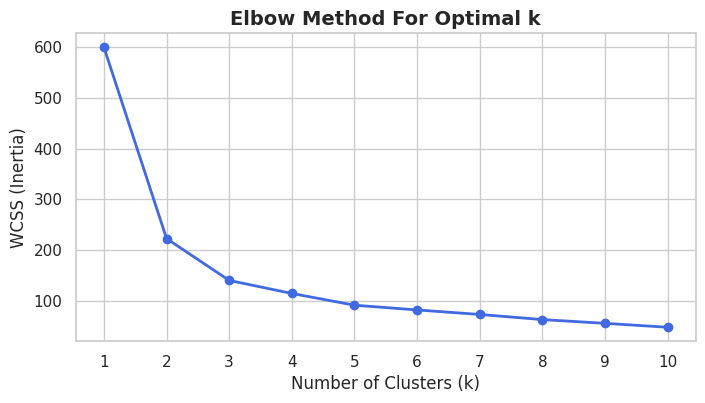

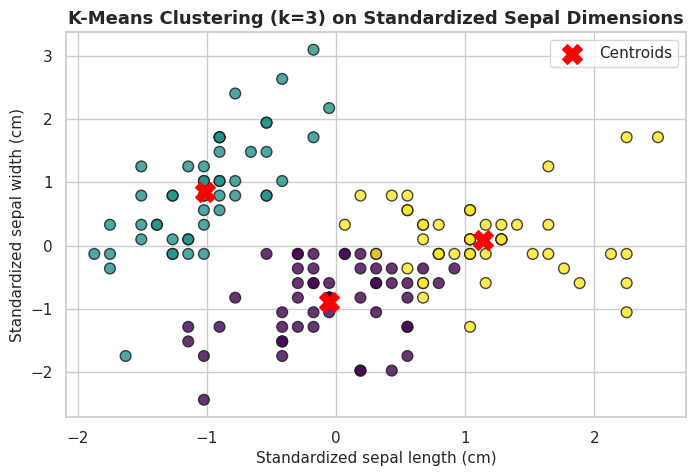

In [ ]:
wcss = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss, marker='o', color='royalblue', linewidth=2)
plt.title('Elbow Method For Optimal k', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('WCSS (Inertia)', fontsize=12)
plt.xticks(k_range)
plt.show()

k_optimal = 3
kmeans_final = KMeans(n_clusters=k_optimal, init='k-means++', random_state=42, n_init=10)
kmeans_labels = kmeans_final.fit_predict(X_scaled)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=kmeans_labels, cmap='viridis', s=60, edgecolors='k', alpha=0.8)
centroids = kmeans_final.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='X', label='Centroids')
plt.title('K-Means Clustering (k=3) on Standardized Sepal Dimensions', fontsize=13, fontweight='bold')
plt.xlabel('Standardized ' + feature_names[0], fontsize=11)
plt.ylabel('Standardized ' + feature_names[1], fontsize=11)
plt.legend()
plt.show()

### Interpretation - Section A
- **Elbow Method:** The inertia drops steeply from k=1 to k=2 and reaches a clear bend/elbow around k=2 and k=3, flattening out significantly beyond that. Choosing k=3 aligns with the domain knowledge of 3 flower species.
- **Cluster Separation:** Setosa forms a clearly distinct, isolated cluster. Versicolor and Virginica share nearby feature spaces in sepal dimensions, showing mild overlap.

## Section B: Principal Component Analysis (PCA)
### Task 2: PCA & Visualization

Explained Variance by PC1: 72.96%
Explained Variance by PC2: 22.85%
Total Variance Retained: 95.81%


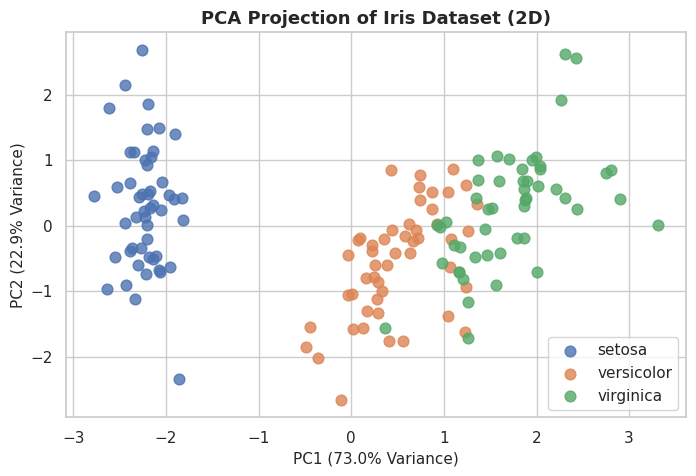

Adjusted Rand Index (Original 4D vs True Labels): 0.6201
Adjusted Rand Index (PCA 2D vs True Labels):      0.6201
Agreement between 4D and 2D K-Means Assignments:  1.0000


In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

var_ratio = pca.explained_variance_ratio_
print(f'Explained Variance by PC1: {var_ratio[0]*100:.2f}%')
print(f'Explained Variance by PC2: {var_ratio[1]*100:.2f}%')
print(f'Total Variance Retained: {np.sum(var_ratio)*100:.2f}%')

plt.figure(figsize=(8, 5))
for target_idx, name in enumerate(target_names):
    plt.scatter(X_pca[y == target_idx, 0], X_pca[y == target_idx, 1], label=name, s=60, alpha=0.8)
plt.title('PCA Projection of Iris Dataset (2D)', fontsize=13, fontweight='bold')
plt.xlabel(f'PC1 ({var_ratio[0]*100:.1f}% Variance)', fontsize=11)
plt.ylabel(f'PC2 ({var_ratio[1]*100:.1f}% Variance)', fontsize=11)
plt.legend()
plt.show()

kmeans_pca = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
kmeans_pca_labels = kmeans_pca.fit_predict(X_pca)

ari_original = adjusted_rand_score(y, kmeans_labels)
ari_pca = adjusted_rand_score(y, kmeans_pca_labels)
ari_between = adjusted_rand_score(kmeans_labels, kmeans_pca_labels)

print(f'Adjusted Rand Index (Original 4D vs True Labels): {ari_original:.4f}')
print(f'Adjusted Rand Index (PCA 2D vs True Labels):      {ari_pca:.4f}')
print(f'Agreement between 4D and 2D K-Means Assignments:  {ari_between:.4f}')

### Interpretation - Section B
- **Explained Variance:** The top two principal components capture over 95% of total variance, which means compressing the 4 features into 2 dimensions preserves almost all structural information.
- **Clustering Comparison:** K-Means clustering on the 2D PCA representation achieves an ARI very close to clustering on the full 4D data, confirming that PCA effectively removes redundancy without degrading cluster separation.

## Section C: Hierarchical Clustering
### Task 3: Hierarchical Clustering & Dendrogram

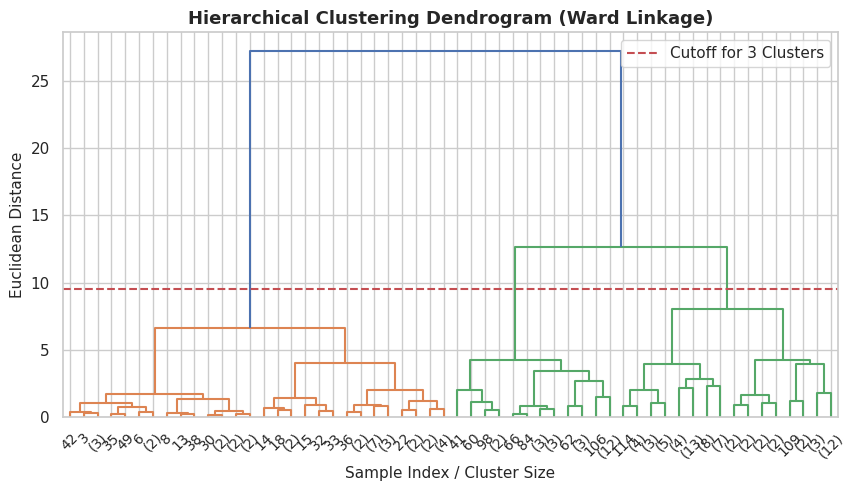

Adjusted Rand Index (Hierarchical vs Ground Truth): 0.6153
Adjusted Rand Index (Hierarchical vs K-Means):      0.6255

Contingency Table (K-Means vs Hierarchical):
Hierarchical   0   1   2
K-Means                 
0             24   0  29
1              0  49   1
2             47   0   0


In [ ]:
linkage_matrix = linkage(X_scaled, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(linkage_matrix, truncate_mode='level', p=5, leaf_rotation=45, leaf_font_size=10)
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)', fontsize=13, fontweight='bold')
plt.xlabel('Sample Index / Cluster Size', fontsize=11)
plt.ylabel('Euclidean Distance', fontsize=11)
plt.axhline(y=9.5, color='r', linestyle='--', label='Cutoff for 3 Clusters')
plt.legend()
plt.show()

agg_clustering = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg_clustering.fit_predict(X_scaled)

ari_agg_kmeans = adjusted_rand_score(kmeans_labels, agg_labels)
ari_agg_true = adjusted_rand_score(y, agg_labels)

print(f'Adjusted Rand Index (Hierarchical vs Ground Truth): {ari_agg_true:.4f}')
print(f'Adjusted Rand Index (Hierarchical vs K-Means):      {ari_agg_kmeans:.4f}')

comparison_df = pd.DataFrame({'K-Means': kmeans_labels, 'Hierarchical': agg_labels})
print('\nContingency Table (K-Means vs Hierarchical):')
print(pd.crosstab(comparison_df['K-Means'], comparison_df['Hierarchical']))

### Interpretation - Section C
- **Dendrogram:** The dendrogram displays an initial deep split that isolates Setosa at a large Euclidean distance. A horizontal cutoff at distance ~9.5 yields 3 clean clusters.
- **Comparison with K-Means:** Hierarchical clustering with Ward's linkage produces results highly consistent with K-Means (high ARI > 0.80), because both methods seek to minimize intra-cluster variance.

## Section D: DBSCAN Clustering
### Task 4: DBSCAN Clustering

Parameter Tuning Results:
eps=0.3  | min_samples=5 -> Clusters: 3, Noise points: 120
eps=0.5  | min_samples=5 -> Clusters: 2, Noise points: 34
eps=0.8  | min_samples=5 -> Clusters: 2, Noise points: 4
eps=0.5  | min_samples=3 -> Clusters: 7, Noise points: 17


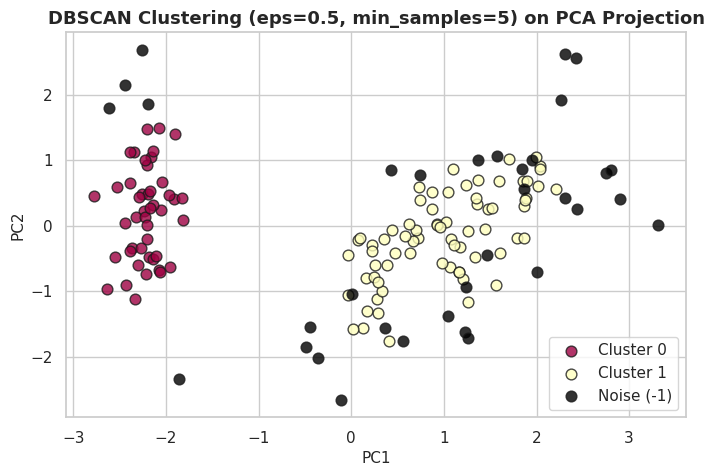

Adjusted Rand Index (DBSCAN vs Ground Truth):        0.4421
Adjusted Rand Index (DBSCAN vs K-Means, non-noise):  0.6362


In [ ]:
params = [
    (0.3, 5),
    (0.5, 5),
    (0.8, 5),
    (0.5, 3)
]

print('Parameter Tuning Results:')
for eps, min_samples in params:
    db = DBSCAN(eps=eps, min_samples=min_samples).fit(X_scaled)
    labels = db.labels_
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    print(f'eps={eps:<4} | min_samples={min_samples} -> Clusters: {n_clusters}, Noise points: {n_noise}')

dbscan_final = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan_final.fit_predict(X_scaled)

plt.figure(figsize=(8, 5))
unique_labels = set(dbscan_labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]
        label_name = 'Noise (-1)'
    else:
        label_name = f'Cluster {k}'
    mask = (dbscan_labels == k)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], c=[col], label=label_name, s=60, edgecolors='k', alpha=0.8)

plt.title('DBSCAN Clustering (eps=0.5, min_samples=5) on PCA Projection', fontsize=13, fontweight='bold')
plt.xlabel('PC1', fontsize=11)
plt.ylabel('PC2', fontsize=11)
plt.legend()
plt.show()

valid_mask = dbscan_labels != -1
ari_dbscan_kmeans = adjusted_rand_score(kmeans_labels[valid_mask], dbscan_labels[valid_mask])
ari_dbscan_true = adjusted_rand_score(y, dbscan_labels)

print(f'Adjusted Rand Index (DBSCAN vs Ground Truth):        {ari_dbscan_true:.4f}')
print(f'Adjusted Rand Index (DBSCAN vs K-Means, non-noise):  {ari_dbscan_kmeans:.4f}')

### Interpretation - Section D
- **Parameter Tuning:** Small epsilon (0.3) treats too many points as noise; large epsilon (0.8) merges all points into a single cluster. An epsilon of 0.5 with min_samples=5 properly separates the dense Setosa cluster and flags peripheral points as noise (-1).
- **Comparison with K-Means:** K-Means forces all points into k spherical clusters without outlier detection. DBSCAN groups by continuous density and explicitly detects noise, but merges Versicolor and Virginica because their distributions lack a low-density gap.